# DSCI 552 — Homework 4

- **Name:** Yiming Lu
- **GitHub Username:** YeeDaco

All imports are in the first code cell (see `requirements.txt`). The data is loaded by the relative path `../data/AReM/`, so the notebook should be run from the `notebook/` folder.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, auc, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:.4f}")
pd.set_option("display.max_columns", 50)

## 1. Time Series Classification Part 1 (from Homework 3)

The code below is the loader from Homework 3. Each file is parsed line by line (comment lines skipped, values split on any run of commas or whitespace), which handles the few badly formatted files (`bending2/dataset4.csv` uses spaces, `cycling/dataset9.csv` and `cycling/dataset14.csv` have trailing commas, `sitting/dataset8.csv` has 479 rows). Test data: datasets 1–2 of `bending1`/`bending2` and datasets 1–3 of the other folders; everything else is training data.

In [2]:
DATA_DIR = Path("../data/AReM")
ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
COLUMNS = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
SERIES = COLUMNS[1:]


def read_arem(path):
    rows = []
    for line in path.read_text().splitlines():
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        values = [v for v in re.split(r"[,\s]+", line) if v]
        rows.append([float(v) for v in values[:7]])
    return pd.DataFrame(rows, columns=COLUMNS)


def file_number(path):
    return int(re.search(r"\d+", path.stem).group())


def is_test(activity, dataset):
    if activity in ("bending1", "bending2"):
        return dataset in (1, 2)
    return dataset in (1, 2, 3)


instances = []
for activity in ACTIVITIES:
    for path in sorted((DATA_DIR / activity).glob("dataset*.csv"), key=file_number):
        dataset = file_number(path)
        instances.append({
            "activity": activity,
            "dataset": dataset,
            "split": "test" if is_test(activity, dataset) else "train",
            "data": read_arem(path)[SERIES].to_numpy(),
        })

print("number of instances:", len(instances))
pd.crosstab(pd.Series([d["activity"] for d in instances], name="activity"),
            pd.Series([d["split"] for d in instances], name="split"), margins=True)

number of instances: 88


split,test,train,All
activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15
All,19,69,88


**Features with the series broken into `l` parts.** In Homework 3, 1(c)iv, the three selected time-domain features were **mean, standard deviation and maximum** (chosen by ANOVA F-statistic on the training set while dropping statistics that are highly correlated with the mean). These three features are used throughout Problem 2.

To break a time series into `l` parts, the 480 rows are split into `l` consecutive blocks of (approximately) equal length with `np.array_split` (block lengths differ by at most 1). The features are computed on each block, so an instance has 6 × l × 3 = 18·l features. The number of instances does not change. Feature names are `<stat><series>` for l = 1 (e.g. `mean2`) and `<stat><series>_p<part>` for l > 1 (e.g. `mean2_p1` is the mean of the first half of `var_rss12` when l = 2). The standard deviation uses ddof = 1.

In [3]:
STAT_FUNCS = {
    "min": np.min,
    "max": np.max,
    "mean": np.mean,
    "median": np.median,
    "std": lambda s: np.std(s, ddof=1),
    "1st quart": lambda s: np.quantile(s, 0.25),
    "3rd quart": lambda s: np.quantile(s, 0.75),
}
SELECTED = ["mean", "std", "max"]   # the three features chosen in HW3 1(c)iv
MAX_L = 20


def instance_features(values, l, stats=SELECTED):
    feats = {}
    blocks = np.array_split(np.arange(len(values)), l)
    for i in range(values.shape[1]):
        for j, idx in enumerate(blocks, start=1):
            seg = values[idx, i]
            for name in stats:
                key = f"{name}{i + 1}" if l == 1 else f"{name}{i + 1}_p{j}"
                feats[key] = STAT_FUNCS[name](seg)
    return feats


def build_features(l, stats=SELECTED):
    rows = [{"activity": d["activity"], "dataset": d["dataset"], "split": d["split"],
             **instance_features(d["data"], l, stats)} for d in instances]
    return pd.DataFrame(rows)


FEATURES = {l: build_features(l) for l in range(1, MAX_L + 1)}
META = ["activity", "dataset", "split"]


def get_xy(l, split, binary=True):
    df = FEATURES[l][FEATURES[l]["split"] == split]
    X = df.drop(columns=META)
    y = df["activity"].str.startswith("bending").astype(int) if binary else df["activity"]
    return X, y.to_numpy()


print("features per instance for l = 1, 2, 20:", [FEATURES[l].shape[1] - len(META) for l in (1, 2, 20)])
FEATURES[1].head()

features per instance for l = 1, 2, 20: [18, 36, 360]


,activity,dataset,split,mean1,std1,max1,mean2,std2,max2,mean3,std3,max3,mean4,std4,max4,mean5,std5,max5,mean6,std6,max6
0,bending1,1,test,40.6248,1.4770,45.0000,0.3586,0.3226,1.3000,19.0409,4.4630,29.5000,0.8325,0.9657,7.2300,34.3113,2.1884,38.2500,0.5706,0.5829,1.9200
1,bending1,2,test,42.8128,1.4355,45.6700,0.3724,0.2892,1.2200,20.0970,3.8937,29.5000,0.8764,1.0473,5.7600,33.0246,1.9953,38.5000,0.5711,0.6010,3.1100
2,bending1,3,train,43.9545,1.5588,47.4000,0.4263,0.3387,1.7000,22.1224,3.0309,29.7500,0.4973,0.5507,4.4400,35.5885,1.9996,38.5000,0.4933,0.5135,1.7900
3,bending1,4,train,42.1798,3.6707,47.7500,0.6960,0.6309,3.0000,22.1836,3.8105,30.0000,0.9899,0.9537,5.1500,33.4939,3.8494,38.6700,0.6135,0.5243,2.1800
4,bending1,5,train,41.6781,2.2435,45.7500,0.5360,0.4055,2.8300,19.0066,4.0871,28.2500,0.8419,0.9288,6.4200,29.8571,2.4110,37.5000,0.3833,0.3892,1.7900


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary classification using logistic regression

The positive class is **bending** (`bending1` or `bending2`), the negative class is every other activity.

#### i. Scatter plots of mean, std and max of time series 1, 2 and 6 (training set)

training class counts: {'other': 60, 'bending': 9}


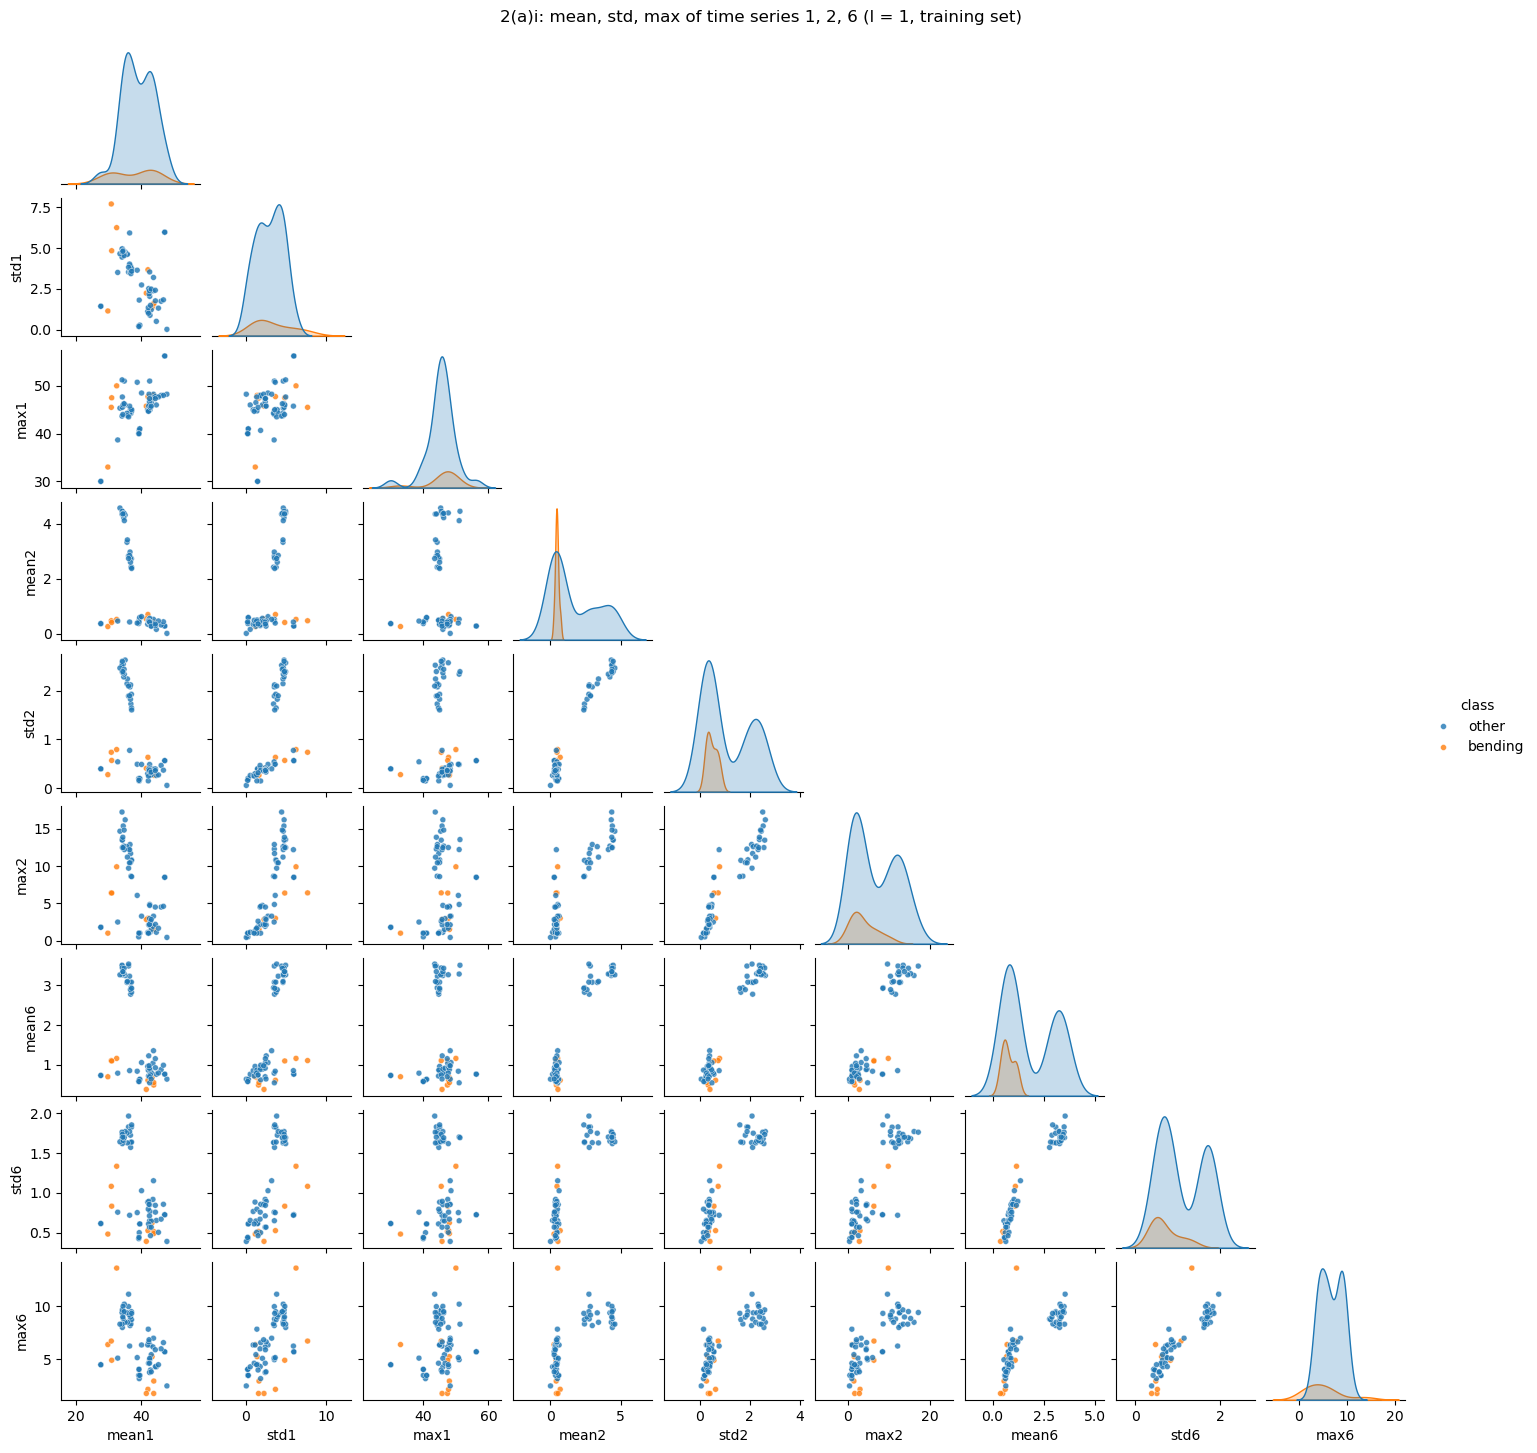

In [4]:
X1_train, y1_train = get_xy(1, "train")
plot_cols = [f"{s}{i}" for i in (1, 2, 6) for s in SELECTED]
plot_df = X1_train[plot_cols].copy()
plot_df["class"] = np.where(y1_train == 1, "bending", "other")
print("training class counts:", plot_df["class"].value_counts().to_dict())
g = sns.pairplot(plot_df, vars=plot_cols, hue="class", hue_order=["other", "bending"],
                 palette={"other": "tab:blue", "bending": "tab:orange"},
                 plot_kws={"s": 18, "alpha": 0.8}, height=1.6, corner=True)
g.fig.suptitle("2(a)i: mean, std, max of time series 1, 2, 6 (l = 1, training set)", y=1.01)
plt.show()

**Observations.** Bending (orange) is easy to separate from the dynamic activities: cycling and walking have a large `mean2`, `std2`, `mean6` and `std6` (lots of movement, so the variance series `var_rss12`/`var_rss23` are large), and they form a separate cluster on the upper right of every panel that involves those features. Bending sits with the low-movement group. Within the low-movement group (lying, sitting, standing, bending) no single feature separates bending perfectly, but `mean1` (bending instances have a lower average RSS between the chest and the ankle sensors) and `max6` / `std1` (bending has occasional larger peaks) place most bending points at the edge of the cloud. So in this 9-dimensional space the two classes look almost — though not obviously perfectly — separable.

#### ii. Break each series into two halves (l = 2) and repeat the scatter plots

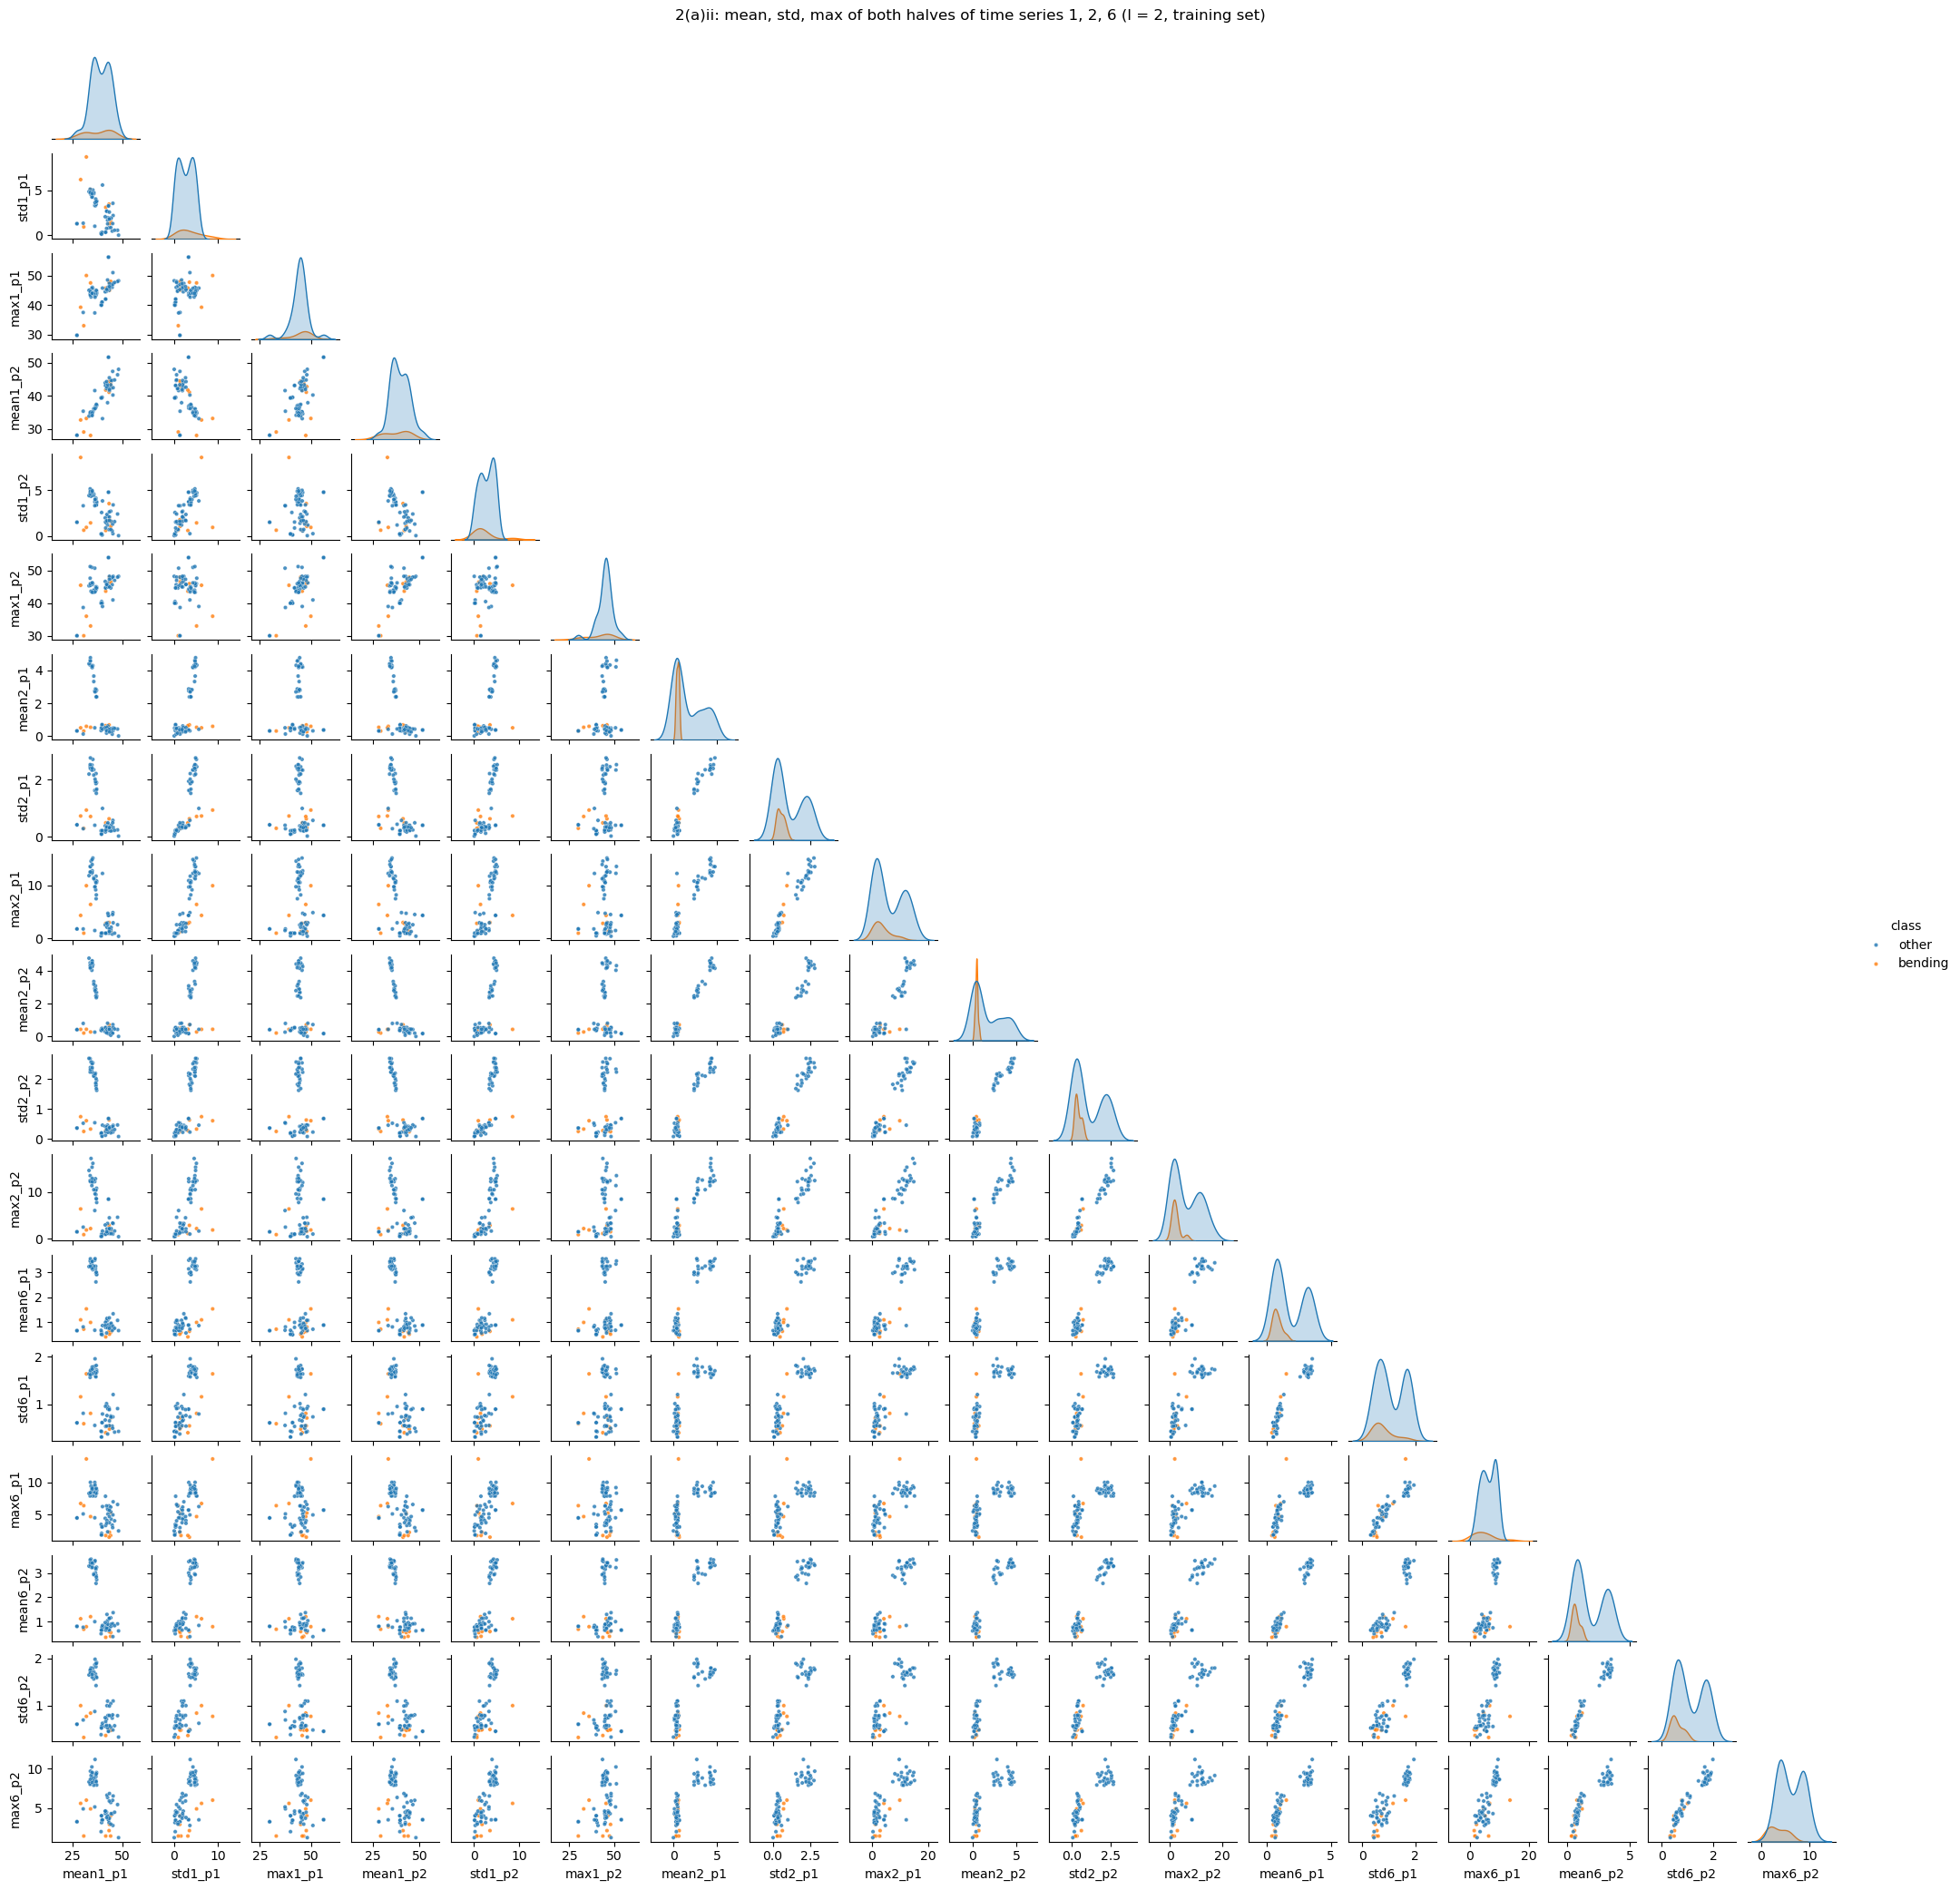

In [5]:
X2_train, y2_train = get_xy(2, "train")
plot_cols2 = [f"{s}{i}_p{j}" for i in (1, 2, 6) for j in (1, 2) for s in SELECTED]
plot_df2 = X2_train[plot_cols2].copy()
plot_df2["class"] = np.where(y2_train == 1, "bending", "other")
g = sns.pairplot(plot_df2, vars=plot_cols2, hue="class", hue_order=["other", "bending"],
                 palette={"other": "tab:blue", "bending": "tab:orange"},
                 plot_kws={"s": 10, "alpha": 0.8}, height=1.15, corner=True)
g.fig.suptitle("2(a)ii: mean, std, max of both halves of time series 1, 2, 6 (l = 2, training set)", y=1.01)
plt.show()

To compare with 2(a)i directly, the next figure plots each feature computed on the whole series (x axis) against the same feature computed on the first and on the second half (y axis).

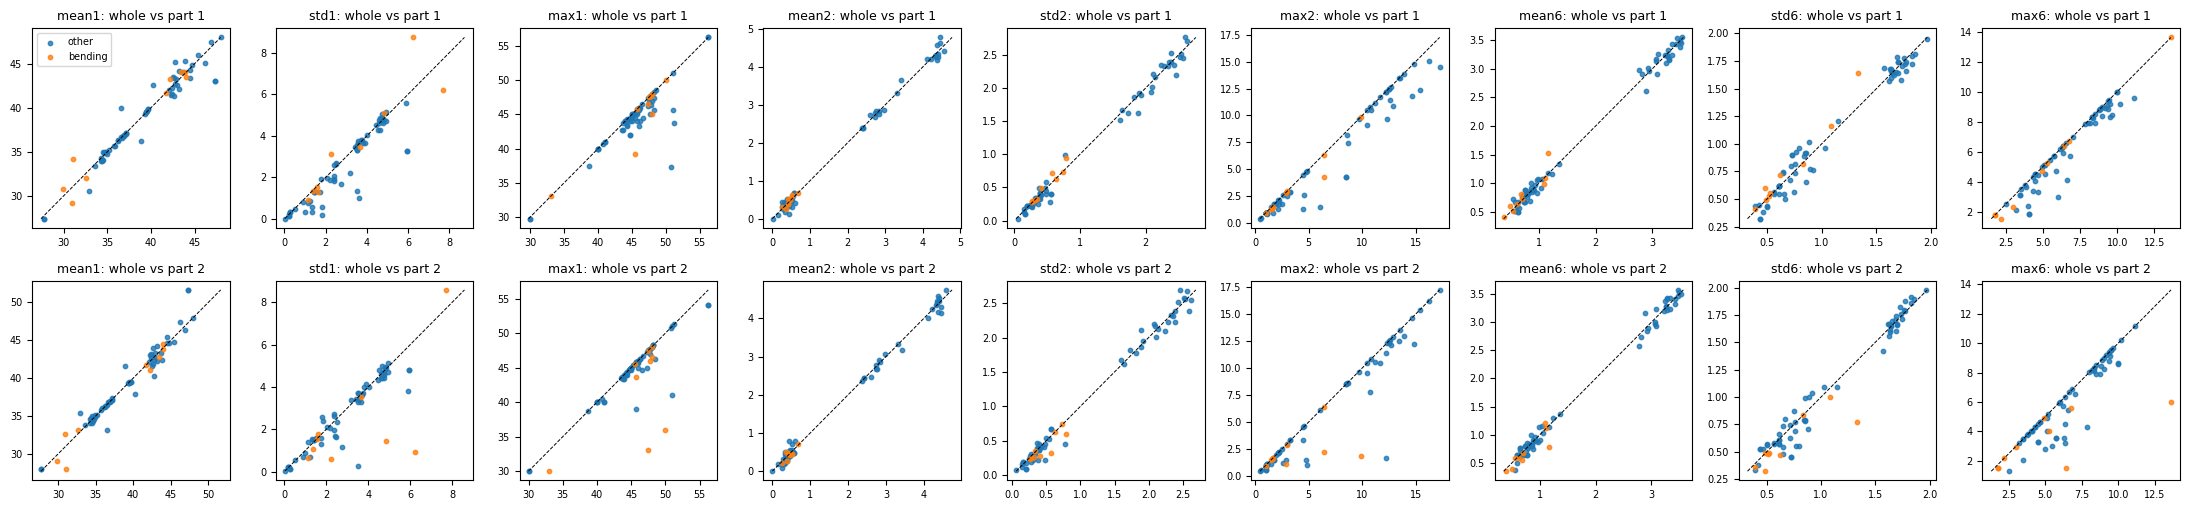

In [6]:
fig, axes = plt.subplots(2, 9, figsize=(22, 5.2))
for c, col in enumerate(plot_cols):
    for r in (0, 1):
        ax = axes[r, c]
        half = X2_train[f"{col}_p{r + 1}"]
        for lab, color, name in ((0, "tab:blue", "other"), (1, "tab:orange", "bending")):
            m = y2_train == lab
            ax.scatter(X1_train[col][m], half[m], s=10, c=color, label=name, alpha=0.8)
        lim = [min(X1_train[col].min(), half.min()), max(X1_train[col].max(), half.max())]
        ax.plot(lim, lim, "k--", lw=0.7)
        ax.set_title(f"{col}: whole vs part {r + 1}", fontsize=9)
        ax.tick_params(labelsize=7)
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.show()

**Is there a considerable difference from 2(a)i? No.** The features of each half lie close to the diagonal in the second figure, i.e. the mean, std and max of a half are almost the same as those of the whole series. That is expected: each instance is one person doing one activity for 2 minutes, so the signal is roughly stationary and each 1-minute half looks like the whole. The pair plots for l = 2 therefore show the same picture as for l = 1 — the dynamic activities form a separate cluster and bending lies on the edge of the low-movement cluster. The only visible changes are that the halves are a little noisier (the std and max of a shorter window vary more; some points fall well below the diagonal for `max` and `std`, since a peak happens in only one half), and that there are now twice as many (highly correlated) features. Splitting adds features but not much new information.

#### iii. Choosing (l, p) with logistic regression + recursive feature elimination

**Model.** For each l ∈ {1, …, 20}, the features are standardized and recursive feature elimination (RFE, a backward selection) is run with a plain logistic regression (`penalty=None`, i.e. no L2 penalty). Because the data turn out to be (almost) separable, the optimizer is stopped early with `max_iter = 100` (footnote 5), which keeps the coefficients finite. The pair (l, p), where p is the number of features kept by RFE, is chosen by **stratified 5-fold cross-validation**.

**The right way vs. the wrong way to cross-validate.** The feature selection is part of fitting the model, so it must be repeated inside every fold:

- *Wrong way:* run RFE (or compute p-values and prune) on the **whole** training set, then cross-validate only the final logistic regression on the selected columns. The held-out fold has already been used to choose the features, so the CV error is optimistically biased — with 18·l features and only 69 instances, some features will look predictive purely by chance, and the CV estimate will not reveal it. The same applies to the standardization step.
- *Right way:* for every candidate l and for every fold, split first; then, using **only the 4 training folds**, standardize, run RFE to rank the features, keep the top p and fit the logistic regression; finally score that model on the held-out fold. The CV accuracy of (l, p) is the mean over the 5 folds. After (l, p) is chosen, the whole pipeline is refit on the full training set. l is chosen the same way: since it changes the number of features, it is just another hyper-parameter of the pipeline (like the number of components in PCR).

**Stratified CV.** There are only 9 bending instances out of 69 training instances (13%). A plain random 5-fold split could give a fold with very few or no bending instances, which makes the fold accuracy meaningless (and a model trained without positives cannot be fit). Stratified K-fold splits each class separately so that every fold has (almost) the same class proportions as the whole training set — here each fold has 1–2 bending and 12 other instances. So `StratifiedKFold(n_splits=5, shuffle=True)` is used, and the same folds are used for every l.

**Implementation.** RFE with `step=1` removes one feature at a time, so the subsets it produces are nested: the subset of size p is exactly the p features with the best RFE ranking when RFE is run down to 1 feature. So in each fold RFE is run once to get the full ranking, and then a logistic regression is fit on the top-p features for p = 1, …, min(18·l, 20). (More than 20 features for 55 training instances per fold would be pointless.)

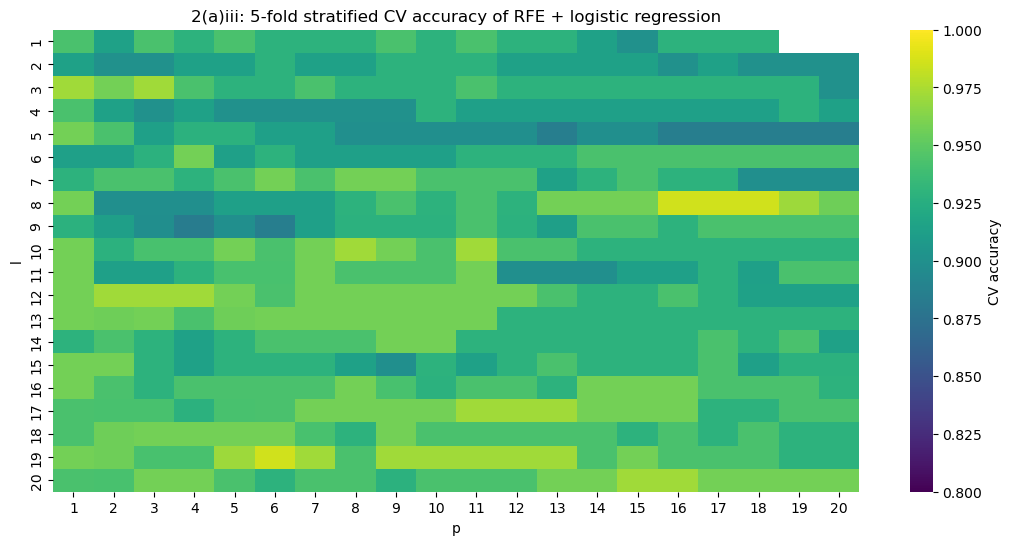

In [7]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)
P_MAX = 20


def plain_logreg(max_iter=100):
    return LogisticRegression(penalty=None, solver="lbfgs", max_iter=max_iter)


def rfe_ranking(X, y):
    rfe = RFE(plain_logreg(), n_features_to_select=1, step=1).fit(X, y)
    return rfe.ranking_


def cv_rfe(l):
    X, y = get_xy(l, "train")
    X = X.to_numpy()
    p_values = range(1, min(X.shape[1], P_MAX) + 1)
    acc = np.zeros((CV.get_n_splits(), len(p_values)))
    for f, (tr, va) in enumerate(CV.split(X, y)):
        scaler = StandardScaler().fit(X[tr])
        Xtr, Xva = scaler.transform(X[tr]), scaler.transform(X[va])
        order = np.argsort(rfe_ranking(Xtr, y[tr]))
        for k, p in enumerate(p_values):
            cols = order[:p]
            model = plain_logreg().fit(Xtr[:, cols], y[tr])
            acc[f, k] = accuracy_score(y[va], model.predict(Xva[:, cols]))
    return pd.DataFrame({"l": l, "p": list(p_values), "cv_accuracy": acc.mean(axis=0),
                         "cv_std": acc.std(axis=0)})


cv_results = pd.concat([cv_rfe(l) for l in range(1, MAX_L + 1)], ignore_index=True)
acc_grid = cv_results.pivot(index="l", columns="p", values="cv_accuracy")
plt.figure(figsize=(13, 6))
sns.heatmap(acc_grid, cmap="viridis", vmin=0.8, vmax=1.0, cbar_kws={"label": "CV accuracy"})
plt.title("2(a)iii: 5-fold stratified CV accuracy of RFE + logistic regression")
plt.show()

In [8]:
best_acc = cv_results["cv_accuracy"].max()
ties = cv_results[np.isclose(cv_results["cv_accuracy"], best_acc)].sort_values(["p", "l"])
print(f"best CV accuracy = {best_acc:.4f}, reached by {len(ties)} (l, p) pairs")
best_l, best_p = int(ties.iloc[0]["l"]), int(ties.iloc[0]["p"])
print(f"chosen (l, p) = ({best_l}, {best_p})  [ties broken by fewest features p, then smallest l]")
print(ties.to_string(index=False))
print("best CV accuracy for each l:")
cv_results.loc[cv_results.groupby("l")["cv_accuracy"].idxmax()].set_index("l").T

best CV accuracy = 0.9857, reached by 4 (l, p) pairs
chosen (l, p) = (19, 6)  [ties broken by fewest features p, then smallest l]
 l  p  cv_accuracy  cv_std
19  6       0.9857  0.0286
 8 16       0.9857  0.0286
 8 17       0.9857  0.0286
 8 18       0.9857  0.0286
best CV accuracy for each l:


l,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
p,1.0000,6.0000,1.0000,1.0000,1.0000,4.0000,6.0000,16.0000,11.0000,8.0000,1.0000,2.0000,1.0000,9.0000,1.0000,1.0000,11.0000,3.0000,6.0000,15.0000
cv_accuracy,0.9429,0.9286,0.9714,0.9429,0.9571,0.9571,0.9571,0.9857,0.9429,0.9714,0.9571,0.9714,0.9571,0.9571,0.9571,0.9571,0.9714,0.9571,0.9857,0.9714
cv_std,0.0286,0.0452,0.0350,0.0535,0.0350,0.0350,0.0350,0.0286,0.0535,0.0350,0.0350,0.0350,0.0350,0.0571,0.0350,0.0350,0.0350,0.0571,0.0286,0.0350


**Result.** The CV accuracy is high for every l (0.93–0.99), and the differences between l values are only one or two misclassified instances out of 69 (one instance = 1.4%). The best CV accuracy, **0.9857** (one error in 69), is reached by (l, p) = (19, 6) and by l = 8 with p = 16, 17, 18. Following the rule "fewest features first", the chosen pair is **(l, p) = (19, 6)**. The CV estimate is noisy, so the choice of l should not be over-interpreted: e.g. l = 3 with a single feature already reaches 0.971.

#### iv. Final model on the training set: confusion matrix, ROC, AUC, βᵢ and p-values

The pipeline (standardize → RFE to p features → logistic regression) is refit on the whole training set with the chosen (l, p). The p-values are Wald p-values: the covariance of β̂ is (XᵀWX)⁻¹ with W = diag(p̂ᵢ(1 − p̂ᵢ)), z = β̂ⱼ / SE(β̂ⱼ), and the p-value is 2Φ(−|z|) (the same formula `statsmodels`/`glm` use). The coefficients are for standardized features.

selected features: ['mean5_p3', 'std5_p18', 'max1_p11', 'max5_p3', 'std4_p14', 'std5_p19']
training accuracy = 1.0000
training confusion matrix (1 = bending):
        pred 0  pred 1
true 0      60       0
true 1       0       9
AUC (train) = 1.0000


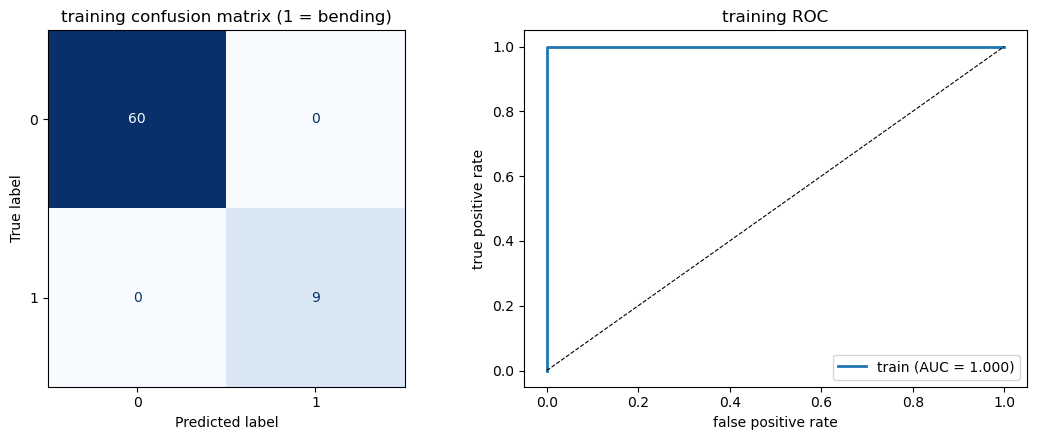

,beta,std. error,z,p-value
intercept,-9.0495,15.5515,-0.5819,0.5606
mean5_p3,4.8712,58.5031,0.0833,0.9336
std5_p18,-2.4274,12.4094,-0.1956,0.8449
max1_p11,-2.6859,11.7020,-0.2295,0.8185
max5_p3,2.3496,70.5715,0.0333,0.9734
std4_p14,-2.3925,17.2290,-0.1389,0.8896
std5_p19,2.0314,13.2369,0.1535,0.8780


In [9]:
def logit_summary(model, X, names):
    prob = model.predict_proba(X)[:, 1]
    Xd = np.column_stack([np.ones(len(X)), X])
    W = prob * (1 - prob)
    cov = np.linalg.pinv(Xd.T @ (Xd * W[:, None]))
    beta = np.r_[model.intercept_, model.coef_.ravel()]
    se = np.sqrt(np.diag(cov))
    z = beta / se
    return pd.DataFrame({"beta": beta, "std. error": se, "z": z, "p-value": 2 * norm.sf(np.abs(z))},
                        index=["intercept"] + list(names))


def show_cm(y_true, y_pred, labels, title, ax=None):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
    (ax or plt.gca()).set_title(title)
    print(f"{title}:")
    print(pd.DataFrame(cm, index=[f"true {c}" for c in labels], columns=[f"pred {c}" for c in labels]).to_string())
    return cm


def plot_roc(y_true, score, label, ax):
    fpr, tpr, _ = roc_curve(y_true, score)
    a = auc(fpr, tpr)
    print(f"AUC ({label}) = {a:.4f}")
    ax.plot(fpr, tpr, lw=2, label=f"{label} (AUC = {a:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
    ax.legend(loc="lower right")
    return a


Xtr_df, ytr = get_xy(best_l, "train")
Xte_df, yte = get_xy(best_l, "test")
scaler_a = StandardScaler().fit(Xtr_df)
Ztr, Zte = scaler_a.transform(Xtr_df), scaler_a.transform(Xte_df)
sel_a = np.argsort(rfe_ranking(Ztr, ytr))[:best_p]
sel_names_a = Xtr_df.columns[sel_a]
model_a = plain_logreg().fit(Ztr[:, sel_a], ytr)
print("selected features:", list(sel_names_a))

ytr_pred = model_a.predict(Ztr[:, sel_a])
ytr_score = model_a.predict_proba(Ztr[:, sel_a])[:, 1]
print(f"training accuracy = {accuracy_score(ytr, ytr_pred):.4f}")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
show_cm(ytr, ytr_pred, [0, 1], "training confusion matrix (1 = bending)", axes[0])
train_auc_a = plot_roc(ytr, ytr_score, "train", axes[1])
axes[1].set_title("training ROC")
plt.tight_layout()
plt.show()
logit_summary(model_a, Ztr[:, sel_a], sel_names_a)

**Training results.** With (l, p) = (19, 6) the selected features are `mean5_p3`, `std5_p18`, `max1_p11`, `max5_p3`, `std4_p14` and `std5_p19`. The training confusion matrix is perfect (60 true negatives, 9 true positives, no errors) and the training ROC is the ideal curve with **AUC = 1.0**.

The table above gives the βᵢ and their p-values. All p-values are very large (0.56–0.97) even though the model classifies the training set perfectly. This does not mean the features are useless; it is the sign of (quasi-)complete separation (see vi): when the classes are separated, the fitted probabilities are all ≈ 0 or ≈ 1, so W = p̂(1 − p̂) ≈ 0, (XᵀWX)⁻¹ and the standard errors blow up, and the Wald test has no power. With separable data the p-values are not reliable for variable selection, which is one reason RFE was used for the selection instead.

#### v. Test set

test accuracy = 0.9474   vs   CV accuracy = 0.9857
test confusion matrix (1 = bending):
        pred 0  pred 1
true 0      15       0
true 1       1       3
AUC (test) = 0.8500


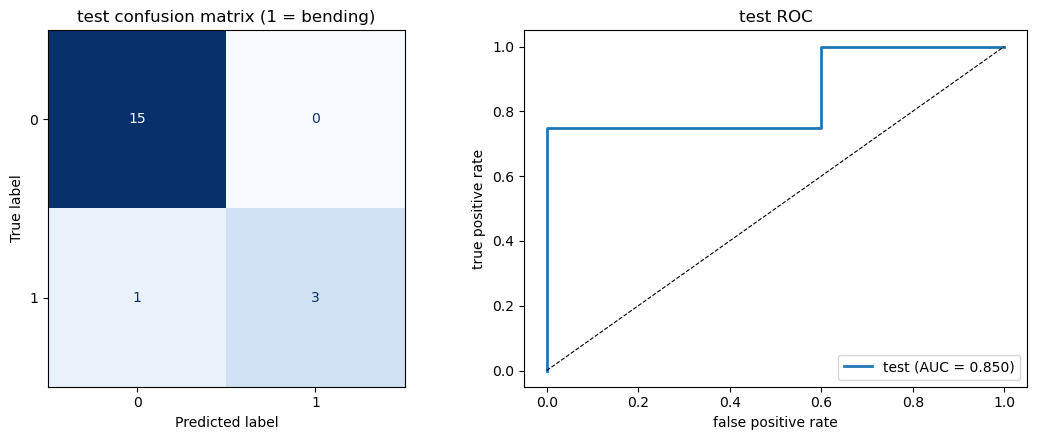

In [10]:
yte_pred = model_a.predict(Zte[:, sel_a])
yte_score = model_a.predict_proba(Zte[:, sel_a])[:, 1]
test_acc_a = accuracy_score(yte, yte_pred)
cv_acc_a = cv_results.query("l == @best_l and p == @best_p")["cv_accuracy"].item()
print(f"test accuracy = {test_acc_a:.4f}   vs   CV accuracy = {cv_acc_a:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
show_cm(yte, yte_pred, [0, 1], "test confusion matrix (1 = bending)", axes[0])
plot_roc(yte, yte_score, "test", axes[1])
axes[1].set_title("test ROC")
plt.tight_layout()
plt.show()

**Test vs. CV.** The test accuracy is **0.947** (18 of 19 correct: all 15 non-bending instances are correct and 1 of the 4 bending instances is missed), while the CV accuracy was **0.986**. The two numbers differ by about one instance; with only 19 test instances one error costs 5.3%, so the test accuracy is consistent with the CV estimate, which is slightly optimistic as expected (it is also the maximum over 400 (l, p) pairs, so it carries some selection bias). The test AUC is 0.85: the missed bending instance gets a lower score than some non-bending instances.

#### vi. Are the classes well separated (unstable logistic regression)?

If the classes are linearly separable, the maximum-likelihood estimate does not exist: the likelihood keeps increasing as ‖β‖ → ∞. A simple check is to fit the unpenalized model with more and more iterations and watch the coefficients and the training log-likelihood.

In [11]:
rows = []
for it in (10, 50, 100, 500, 2000, 10000):
    m = plain_logreg(max_iter=it).fit(Ztr[:, sel_a], ytr)
    prob = m.predict_proba(Ztr[:, sel_a])[:, 1]
    rows.append({"max_iter": it, "iterations used": int(m.n_iter_[0]),
                 "||beta||": np.linalg.norm(np.r_[m.intercept_, m.coef_.ravel()]),
                 "train accuracy": accuracy_score(ytr, m.predict(Ztr[:, sel_a])),
                 "log-likelihood": np.sum(ytr * np.log(prob + 1e-300) + (1 - ytr) * np.log(1 - prob + 1e-300))})
pd.DataFrame(rows).set_index("max_iter")

,iterations used,||beta||,train accuracy,log-likelihood
max_iter,,,,
10,10,9.6520,1.0000,-0.0350
50,12,11.5801,1.0000,-0.0093
100,12,11.5801,1.0000,-0.0093
500,12,11.5801,1.0000,-0.0093
2000,12,11.5801,1.0000,-0.0093
10000,12,11.5801,1.0000,-0.0093


**Yes, the classes are (completely) separated in the selected feature space.** The training accuracy is 100%, the log-likelihood is almost 0 (−0.009; its supremum is 0), and the coefficients are large in standardized units (|β| ≈ 2–9). With separable data the MLE does not exist: the likelihood keeps increasing as β is scaled up, so an unconstrained optimizer pushes ‖β‖ toward infinity and the answer depends on when it stops. Here lbfgs stops after 12 iterations only because the gradient falls below its tolerance — the coefficients are effectively arbitrary along the separating direction. The instability also shows up as the huge standard errors and p-values ≈ 1 in iv. Stopping early (`max_iter`, footnote 5) or using a penalty (as in part (b)) keeps the coefficients finite.

#### vii. Class imbalance and case-control sampling

In [12]:
print("training set:", dict(zip(*np.unique(ytr, return_counts=True))), " test set:", dict(zip(*np.unique(yte, return_counts=True))))

training set: {0: 60, 1: 9}  test set: {0: 15, 1: 4}


**Yes, the classes are imbalanced:** 9 bending vs. 60 other instances in the training set (13% vs. 87%) and 4 vs. 15 in the test set. In the confusion matrices above, the only error is on the rare class (a missed bending instance), which is typical of imbalance.

**Case-control sampling.** Keep all 9 cases (bending) and sample the same number of controls (other) at random, so the sample is balanced (π̃ = 0.5), and fit logistic regression on this sample. Sampling on the response only changes the intercept, not the slopes, so the intercept is corrected (ISLR §4.3):

β̂₀* = β̂₀ + log(π / (1 − π)) − log(π̃ / (1 − π̃)),

where π = 9/69 is the prevalence of bending in the training population. The same (l, p) and the same 6 selected features as in iv are used.

pi = 0.1304, pi~ = 0.5000, intercept: -7.8595 -> -9.7566
intercept   -9.7566
mean5_p3     4.6604
std5_p18    -3.2210
max1_p11    -3.0231
max5_p3      2.2988
std4_p14    -3.4561
std5_p19     1.4445
case-control model: full training set:
        pred 0  pred 1
true 0      60       0
true 1       0       9
full training set: accuracy = 1.0000
case-control model: test set:
        pred 0  pred 1
true 0      15       0
true 1       1       3
test set: accuracy = 0.9474
AUC (train) = 1.0000
AUC (test) = 0.8167


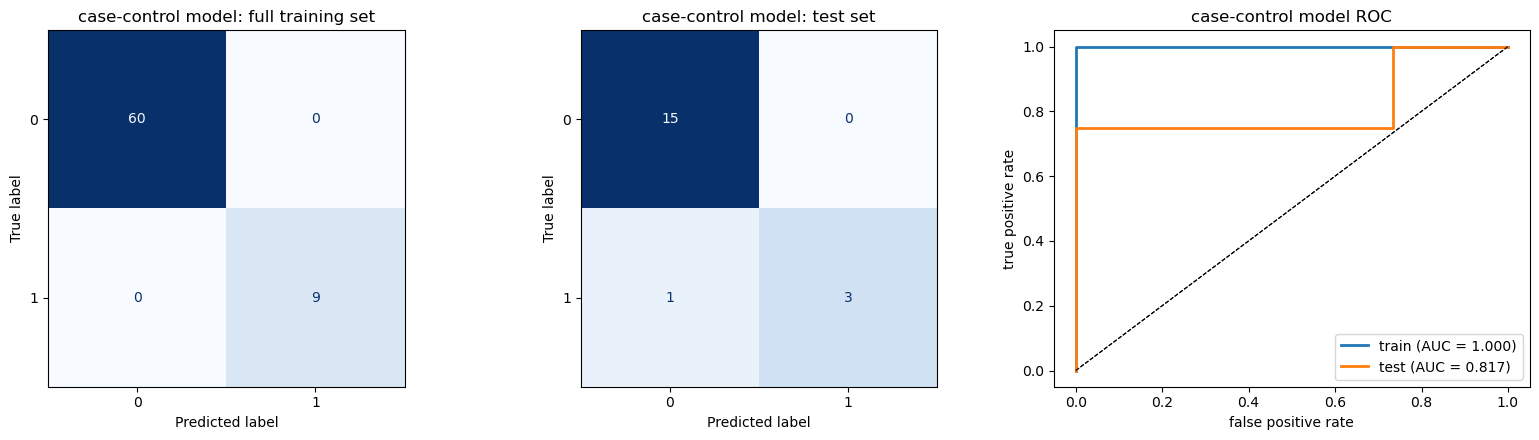

In [13]:
rng = np.random.default_rng(552)
cases = np.flatnonzero(ytr == 1)
controls = rng.choice(np.flatnonzero(ytr == 0), size=len(cases), replace=False)
cc_idx = np.r_[cases, controls]
model_cc = plain_logreg().fit(Ztr[cc_idx][:, sel_a], ytr[cc_idx])

pi = ytr.mean()                        # prevalence of bending in the training data
pi_tilde = ytr[cc_idx].mean()          # prevalence in the case-control sample (= 0.5)
shift = np.log(pi / (1 - pi)) - np.log(pi_tilde / (1 - pi_tilde))
beta0_raw = model_cc.intercept_[0]
model_cc.intercept_ = model_cc.intercept_ + shift
print(f"pi = {pi:.4f}, pi~ = {pi_tilde:.4f}, intercept: {beta0_raw:.4f} -> {model_cc.intercept_[0]:.4f}")
print(pd.Series(np.r_[model_cc.intercept_, model_cc.coef_.ravel()], index=["intercept"] + list(sel_names_a),
                name="adjusted beta").to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (Z, y, name) in zip(axes[:2], ((Ztr, ytr, "full training set"), (Zte, yte, "test set"))):
    pred = model_cc.predict(Z[:, sel_a])
    show_cm(y, pred, [0, 1], f"case-control model: {name}", ax)
    print(f"{name}: accuracy = {accuracy_score(y, pred):.4f}")
for Z, y, name in ((Ztr, ytr, "train"), (Zte, yte, "test")):
    plot_roc(y, model_cc.predict_proba(Z[:, sel_a])[:, 1], name, axes[2])
axes[2].set_title("case-control model ROC")
plt.tight_layout()
plt.show()

**Case-control results.** The intercept moves from −7.86 to −9.76 after the adjustment. On the full training set the case-control model again classifies all 69 instances correctly (AUC = 1.0); on the test set it has the same confusion matrix as the full model (15 TN, 3 TP, 1 FN, accuracy 0.947), with test AUC ≈ 0.82. So case-control sampling neither helps nor hurts much here: the classes are already separable in the training data, and with only 9 cases the balanced sample has just 18 instances, so the fit is noisier. Its main benefit — a cheaper fit with a correct intercept when controls are plentiful — does not matter for a 69-instance data set. The intercept correction does not change the AUC (it shifts all scores by the same constant); it only moves the classification threshold.

### (b) Binary classification using L1-penalized logistic regression

#### i. Cross-validating l and the budget C

Instead of RFE, the L1 penalty does the variable selection. The pipeline is `StandardScaler → LogisticRegression(penalty="l1", solver="liblinear", C)`; in scikit-learn C = 1/λ, so a small C is a strong penalty. For every l ∈ {1, …, 20} and every C on a log grid from 10⁻² to 10³, the stratified 5-fold CV accuracy is computed with the **same folds** as in 2(a)iii, and the standardization is fit inside each fold. Ties are broken by the smallest l, then the smallest C (the sparsest model).

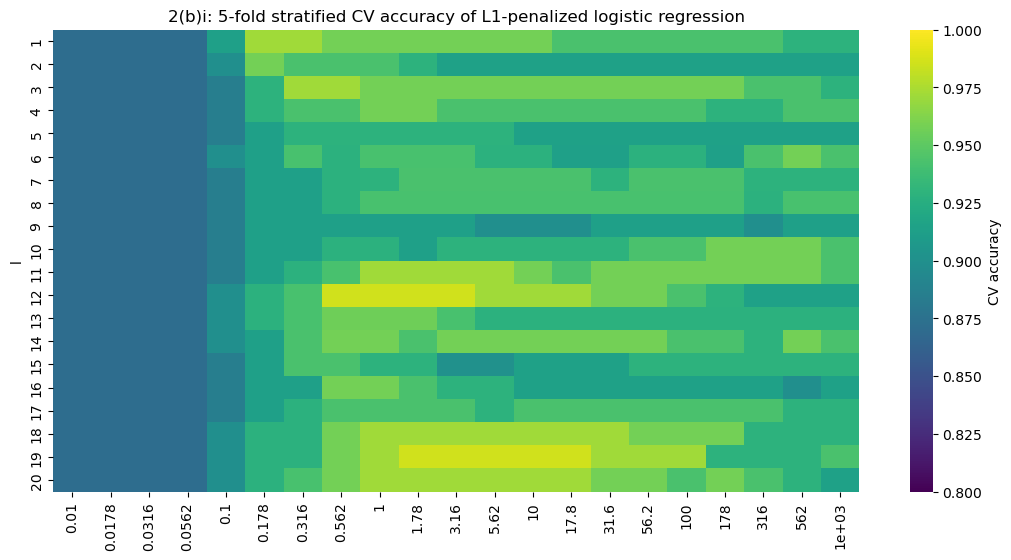

best CV accuracy = 0.9857; chosen l = 12, C = 0.5623 (lambda = 1/C = 1.778)


In [14]:
C_GRID = np.logspace(-2, 3, 21)


def cv_score(make_model, X, y, cv=CV):
    scores = []
    for tr, va in cv.split(X, y):
        m = make_model().fit(X[tr], y[tr])
        scores.append(accuracy_score(y[va], m.predict(X[va])))
    return np.mean(scores)


def l1_binary(C):
    return make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=1000, random_state=552))


rows = []
for l in range(1, MAX_L + 1):
    X, y = get_xy(l, "train")
    X = X.to_numpy()
    for C in C_GRID:
        rows.append({"l": l, "C": C, "cv_accuracy": cv_score(lambda: l1_binary(C), X, y)})
cv_l1 = pd.DataFrame(rows)

plt.figure(figsize=(13, 6))
grid = cv_l1.pivot(index="l", columns="C", values="cv_accuracy")
grid.columns = [f"{c:.3g}" for c in grid.columns]
sns.heatmap(grid, cmap="viridis", vmin=0.8, vmax=1.0, cbar_kws={"label": "CV accuracy"})
plt.title("2(b)i: 5-fold stratified CV accuracy of L1-penalized logistic regression")
plt.show()

best_acc_l1 = cv_l1["cv_accuracy"].max()
best_row = cv_l1[np.isclose(cv_l1["cv_accuracy"], best_acc_l1)].sort_values(["l", "C"]).iloc[0]
best_l1, best_C = int(best_row["l"]), best_row["C"]
print(f"best CV accuracy = {best_acc_l1:.4f}; chosen l = {best_l1}, C = {best_C:.4g} (lambda = 1/C = {1 / best_C:.4g})")

non-zero coefficients: 5 of 216
max1_p7     -0.5212
std3_p3      0.0154
mean5_p2     1.8550
mean5_p11    0.1888
max6_p11    -0.4901
intercept: -2.5322
L1 logistic: train:
        pred 0  pred 1
true 0      60       0
true 1       0       9
train accuracy = 1.0000
AUC (train) = 1.0000
L1 logistic: test:
        pred 0  pred 1
true 0      15       0
true 1       1       3
test accuracy = 0.9474
AUC (test) = 0.9833


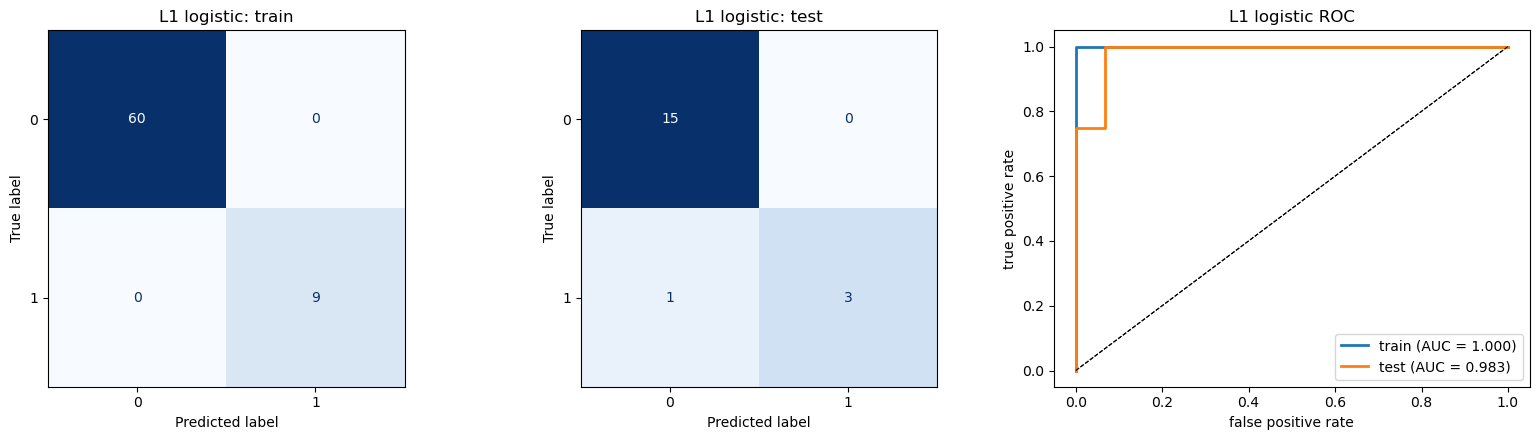

In [15]:
Xtr_b, ytr_b = get_xy(best_l1, "train")
Xte_b, yte_b = get_xy(best_l1, "test")
model_b = l1_binary(best_C).fit(Xtr_b, ytr_b)
coef_b = pd.Series(model_b[-1].coef_.ravel(), index=Xtr_b.columns)
print(f"non-zero coefficients: {(coef_b != 0).sum()} of {len(coef_b)}")
print(coef_b[coef_b != 0].to_string())
print(f"intercept: {model_b[-1].intercept_[0]:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (X, y, name) in zip(axes[:2], ((Xtr_b, ytr_b, "train"), (Xte_b, yte_b, "test"))):
    pred = model_b.predict(X)
    show_cm(y, pred, [0, 1], f"L1 logistic: {name}", ax)
    print(f"{name} accuracy = {accuracy_score(y, pred):.4f}")
    plot_roc(y, model_b.predict_proba(X)[:, 1], name, axes[2])
axes[2].set_title("L1 logistic ROC")
plt.tight_layout()
plt.show()
test_acc_b = accuracy_score(yte_b, model_b.predict(Xte_b))

**Result.** The best CV accuracy is **0.9857**, the same as with RFE. The chosen pair is **l = 12, C ≈ 0.56 (λ = 1/C ≈ 1.78)**. The L1 penalty keeps only **5 of the 216** features; `mean5_p2` (the mean of `avg_rss23` in the second block) has by far the largest weight, followed by `max1_p7` and `max6_p11`. The model is perfect on the training set (AUC 1.0) and has **test accuracy 0.947** (the same single missed bending instance), with a **test AUC of 0.98** — much higher than the 0.85 of the RFE model: the L1 model ranks the test instances better even though the accuracy at the 0.5 threshold is the same.

#### ii. L1 penalty vs. variable selection with p-values / RFE

In [16]:
pd.DataFrame({
    "chosen l": [best_l, best_l1],
    "features used": [best_p, int((coef_b != 0).sum())],
    "CV accuracy": [cv_acc_a, best_acc_l1],
    "test accuracy": [test_acc_a, test_acc_b],
}, index=["RFE + logistic (2a)", "L1 logistic (2b)"])

,chosen l,features used,CV accuracy,test accuracy
RFE + logistic (2a),19,6,0.9857,0.9474
L1 logistic (2b),12,5,0.9857,0.9474


**Which performs better?** On accuracy the two are tied: the same CV accuracy (0.986) and the same test accuracy (0.947, one missed bending instance out of 19), and both use a handful of features (6 vs. 5). The L1 model has a clearly higher test AUC (0.98 vs. 0.85) and a much more stable fit: the penalty keeps β finite, so it is not affected by the separation problem of 2(a)vi, while the unpenalized model's coefficients and p-values are essentially arbitrary. So **L1-penalized logistic regression performs (slightly) better**.

**Which is easier to implement?** **L1 regularization.** It does selection and fitting in one convex optimization, and the only extra hyper-parameter, C, is tuned by CV with a standard grid search. Selection with p-values / RFE needs a separate selection loop that must be re-run inside every CV fold to avoid the "wrong way" bias, a fit for every subset size p, and p-values that scikit-learn does not provide and that are meaningless under separation.

### (c) Multi-class classification (the realistic case)

#### i. L1-penalized multinomial logistic regression

The same procedure as in 2(b)i is used with 7 classes: `StandardScaler → LogisticRegression(penalty="l1", solver="saga", C)`. With the `saga` solver and more than two classes scikit-learn fits the **multinomial** (softmax) model. l and C are chosen by stratified 5-fold CV on the training set (same tie-breaking). `bending2` has only 4 training instances, so with 5 folds one fold has no `bending2` instance; stratification still spreads the classes as evenly as possible.

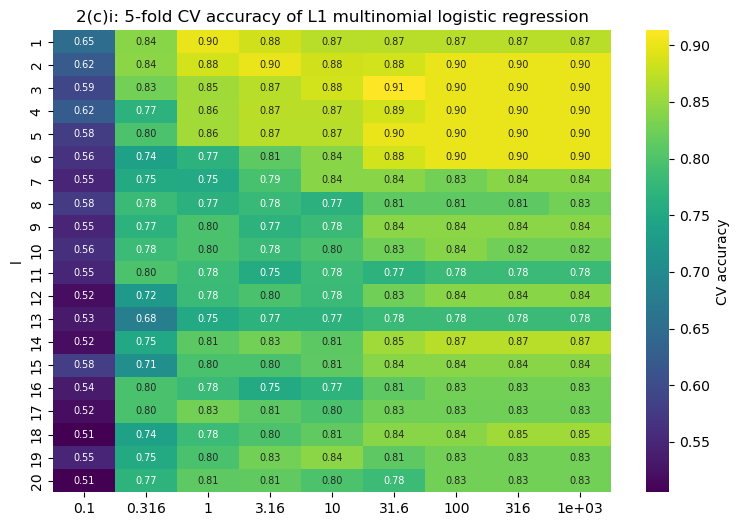

best CV accuracy = 0.9132; chosen l = 3, C = 31.62


In [17]:
C_GRID_MC = np.logspace(-1, 3, 9)
CV_MC = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)


def l1_multinomial(C):
    return make_pipeline(StandardScaler(),
                         LogisticRegression(penalty="l1", solver="saga", C=C, max_iter=5000, tol=1e-3, random_state=552))


rows = []
for l in range(1, MAX_L + 1):
    X, y = get_xy(l, "train", binary=False)
    X = X.to_numpy()
    for C in C_GRID_MC:
        rows.append({"l": l, "C": C, "cv_accuracy": cv_score(lambda: l1_multinomial(C), X, y, CV_MC)})
cv_mc = pd.DataFrame(rows)

plt.figure(figsize=(9, 6))
grid = cv_mc.pivot(index="l", columns="C", values="cv_accuracy")
grid.columns = [f"{c:.3g}" for c in grid.columns]
sns.heatmap(grid, cmap="viridis", annot=True, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"label": "CV accuracy"})
plt.title("2(c)i: 5-fold CV accuracy of L1 multinomial logistic regression")
plt.show()

best_acc_mc = cv_mc["cv_accuracy"].max()
best_row = cv_mc[np.isclose(cv_mc["cv_accuracy"], best_acc_mc)].sort_values(["l", "C"]).iloc[0]
best_l_mc, best_C_mc = int(best_row["l"]), best_row["C"]
print(f"best CV accuracy = {best_acc_mc:.4f}; chosen l = {best_l_mc}, C = {best_C_mc:.4g}")

**Confusion matrix and ROC for more than two classes.** The multiclass confusion matrix is a K × K table whose entry (i, j) counts the instances of true class i predicted as class j; the diagonal holds the correct predictions. A ROC curve needs a binary problem, so for K classes the usual approach is **one-vs-rest**: for each class k, the score is P̂(Y = k | x) and the "positive" label is "the true class is k". This gives K ROC curves and K AUCs. They can be summarized by a **macro average** (average the K AUCs / curves, every class counts equally) or a **micro average** (pool all K × n (label, score) pairs into one binary problem, every instance counts equally). (A one-vs-one version, averaging the AUC over all pairs of classes — Hand & Till's M — is what `pROC::multiclass.roc` in R computes.)

L1 multinomial (l = 3): test confusion matrix:
               pred bending1  pred bending2  pred cycling  pred lying  pred sitting  pred standing  pred walking
true bending1              2              0             0           0             0              0             0
true bending2              0              1             0           0             1              0             0
true cycling               0              0             3           0             0              0             0
true lying                 0              0             0           3             0              0             0
true sitting               0              0             0           0             2              1             0
true standing              0              0             0           1             0              2             0
true walking               0              0             0           0             0              0             3


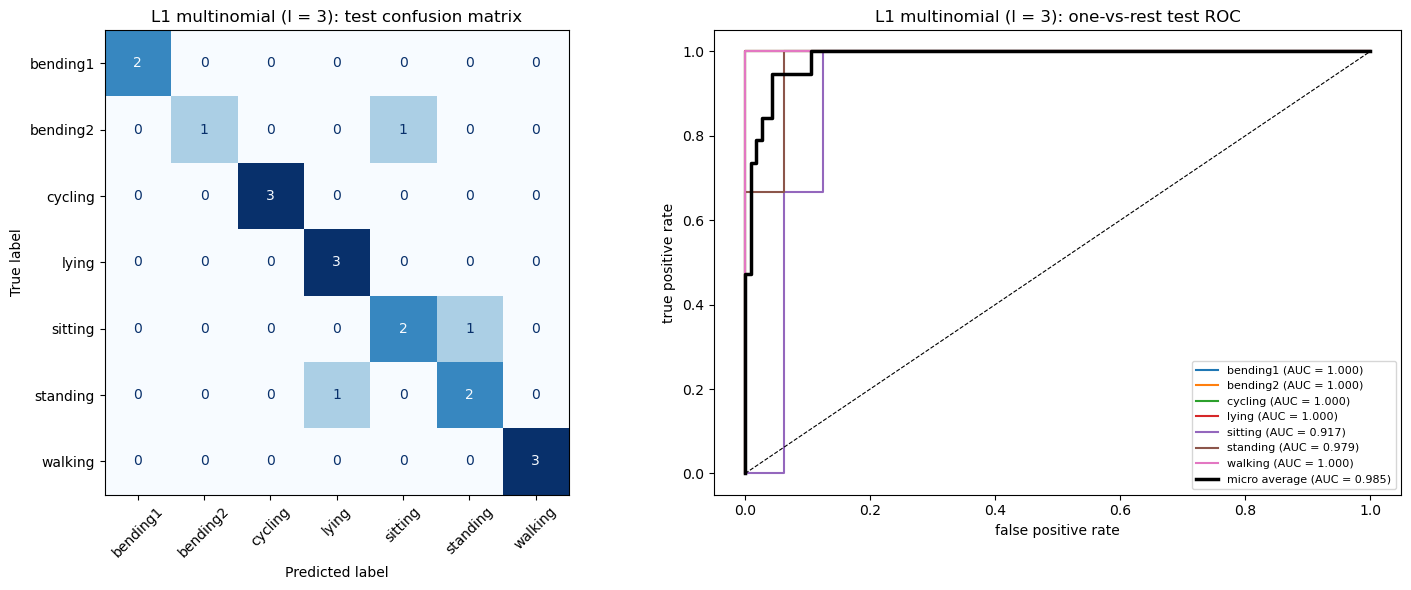

L1 multinomial (l = 3): test error = 0.1579 (accuracy 0.8421)
bending1        1.0000
bending2        1.0000
cycling         1.0000
lying           1.0000
sitting         0.9167
standing        0.9792
walking         1.0000
micro average   0.9852
macro average   0.9851


In [18]:
def evaluate_multiclass(model, Xtr, ytr, Xte, yte, title):
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    err = 1 - accuracy_score(yte, pred)
    classes = model.classes_
    proba = model.predict_proba(Xte)
    Y = label_binarize(yte, classes=classes)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    show_cm(yte, pred, list(classes), f"{title}: test confusion matrix", axes[0])
    axes[0].tick_params(axis="x", rotation=45)
    aucs = {}
    for k, c in enumerate(classes):
        if Y[:, k].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(Y[:, k], proba[:, k])
        aucs[c] = auc(fpr, tpr)
        axes[1].plot(fpr, tpr, lw=1.5, label=f"{c} (AUC = {aucs[c]:.3f})")
    fpr, tpr, _ = roc_curve(Y.ravel(), proba.ravel())
    aucs["micro average"] = auc(fpr, tpr)
    aucs["macro average"] = np.mean([aucs[c] for c in classes])
    axes[1].plot(fpr, tpr, "k-", lw=2.5, label=f"micro average (AUC = {aucs['micro average']:.3f})")
    axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
    axes[1].set_xlabel("false positive rate")
    axes[1].set_ylabel("true positive rate")
    axes[1].set_title(f"{title}: one-vs-rest test ROC")
    axes[1].legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()
    print(f"{title}: test error = {err:.4f} (accuracy {1 - err:.4f})")
    print(pd.Series(aucs, name="test AUC").to_string())
    return err, aucs


Xtr_c, ytr_c = get_xy(best_l_mc, "train", binary=False)
Xte_c, yte_c = get_xy(best_l_mc, "test", binary=False)
err_mc, auc_mc = evaluate_multiclass(l1_multinomial(best_C_mc), Xtr_c, ytr_c, Xte_c, yte_c,
                                     f"L1 multinomial (l = {best_l_mc})")

**Result.** The best CV accuracy is 0.913 at **l = 3, C ≈ 31.6** (a weak penalty). The **test error is 0.158** (16 of 19 correct). The confusion matrix shows that all errors are among the static postures: one `bending2` predicted as `sitting`, one `sitting` predicted as `standing` and one `standing` predicted as `lying`. Cycling, walking, lying and `bending1` are classified perfectly. The one-vs-rest ROC curves are near-perfect for most classes (AUC = 1 for 5 of 7 classes; sitting 0.92, standing 0.98) and the micro- and macro-average AUCs are about 0.985. So the model ranks the classes well, and the remaining errors come from postures (sitting / standing / lying / bending2) whose RSS statistics are similar.

#### ii. Naïve Bayes with Gaussian and multinomial models

Both classifiers use the same mean/std/max features and l is chosen by the same stratified 5-fold CV.

- **Gaussian NB** models each feature within a class as an independent normal variable. It is invariant to rescaling each feature, so the raw features are used.
- **Multinomial NB** treats the feature vector as counts, so the features must be non-negative. All features here are means, standard deviations and maxima of RSS values or of their variances, so they are all ≥ 0 and are used on their raw scale. Its smoothing parameter α is also cross-validated.

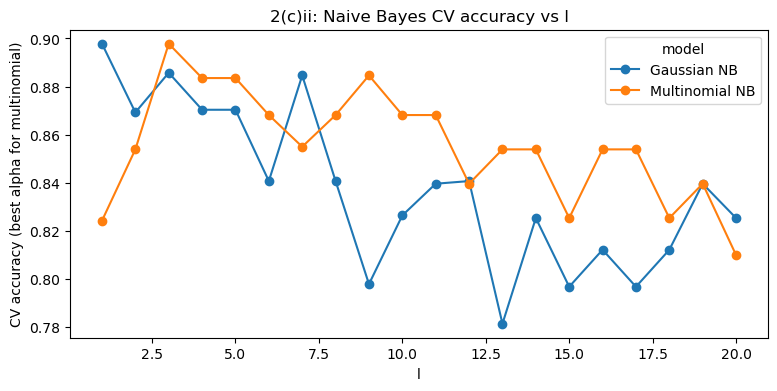

Gaussian NB: best CV accuracy = 0.8978 at l = 1
Multinomial NB: best CV accuracy = 0.8978 at l = 3, alpha = 0.1


In [19]:
ALPHAS = [0.01, 0.1, 1.0, 10.0]
rows = []
for l in range(1, MAX_L + 1):
    X, y = get_xy(l, "train", binary=False)
    X = X.to_numpy()
    assert (X >= 0).all()
    rows.append({"model": "Gaussian NB", "l": l, "alpha": np.nan, "cv_accuracy": cv_score(GaussianNB, X, y, CV_MC)})
    for a in ALPHAS:
        rows.append({"model": "Multinomial NB", "l": l, "alpha": a,
                     "cv_accuracy": cv_score(lambda: MultinomialNB(alpha=a), X, y, CV_MC)})
cv_nb = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 4))
best_per_l = cv_nb.groupby(["model", "l"])["cv_accuracy"].max().unstack(0)
best_per_l.plot(ax=ax, marker="o")
ax.set_ylabel("CV accuracy (best alpha for multinomial)")
ax.set_title("2(c)ii: Naive Bayes CV accuracy vs l")
plt.show()

nb_best = {}
for name, g in cv_nb.groupby("model"):
    top = g[np.isclose(g["cv_accuracy"], g["cv_accuracy"].max())].sort_values(["l", "alpha"]).iloc[0]
    nb_best[name] = top
    print(f"{name}: best CV accuracy = {top['cv_accuracy']:.4f} at l = {int(top['l'])}"
          + ("" if np.isnan(top["alpha"]) else f", alpha = {top['alpha']}"))

Gaussian NB (l = 1): test confusion matrix:
               pred bending1  pred bending2  pred cycling  pred lying  pred sitting  pred standing  pred walking
true bending1              2              0             0           0             0              0             0
true bending2              0              1             0           0             1              0             0
true cycling               0              0             3           0             0              0             0
true lying                 0              0             0           3             0              0             0
true sitting               0              0             0           0             3              0             0
true standing              0              0             0           0             1              2             0
true walking               0              0             0           0             0              0             3


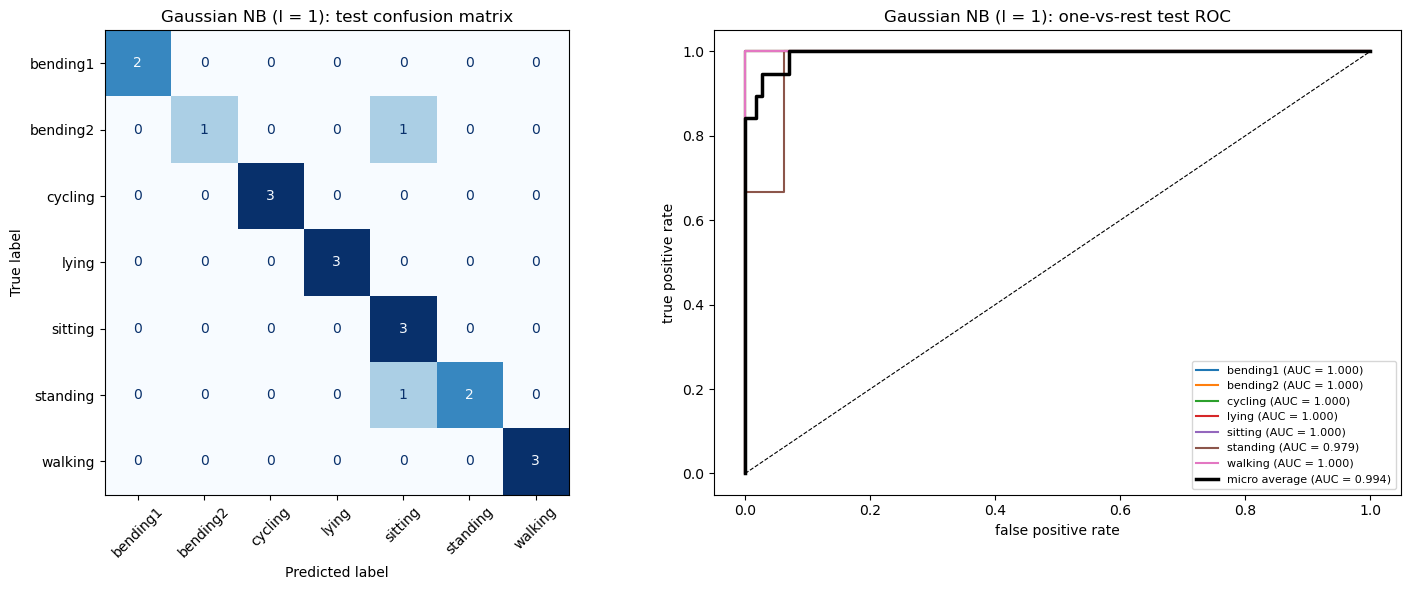

Gaussian NB (l = 1): test error = 0.1053 (accuracy 0.8947)
bending1        1.0000
bending2        1.0000
cycling         1.0000
lying           1.0000
sitting         1.0000
standing        0.9792
walking         1.0000
micro average   0.9940
macro average   0.9970


In [20]:
l_g = int(nb_best["Gaussian NB"]["l"])
err_g, auc_g = evaluate_multiclass(GaussianNB(), *get_xy(l_g, "train", False), *get_xy(l_g, "test", False),
                                   f"Gaussian NB (l = {l_g})")

Multinomial NB (l = 3): test confusion matrix:
               pred bending1  pred bending2  pred cycling  pred lying  pred sitting  pred standing  pred walking
true bending1              2              0             0           0             0              0             0
true bending2              0              2             0           0             0              0             0
true cycling               0              0             3           0             0              0             0
true lying                 0              0             0           2             1              0             0
true sitting               0              0             0           0             2              1             0
true standing              0              0             0           1             0              2             0
true walking               0              0             0           0             0              0             3


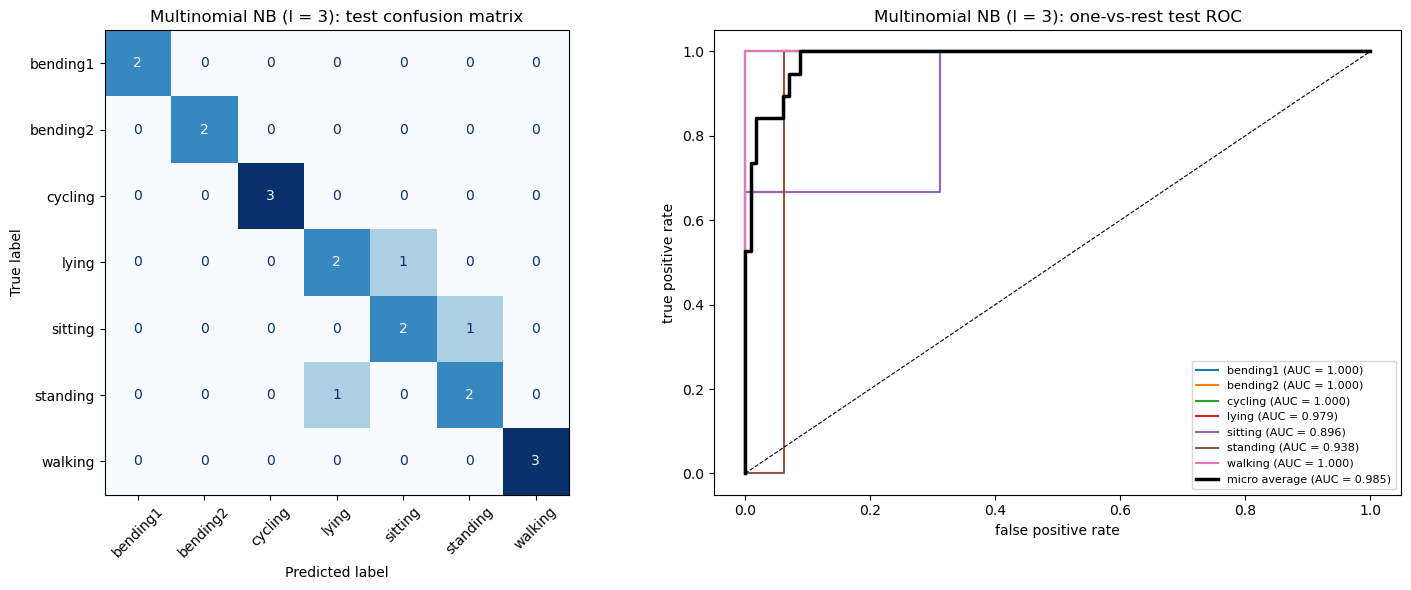

Multinomial NB (l = 3): test error = 0.1579 (accuracy 0.8421)
bending1        1.0000
bending2        1.0000
cycling         1.0000
lying           0.9792
sitting         0.8958
standing        0.9375
walking         1.0000
micro average   0.9848
macro average   0.9732


In [21]:
l_m, a_m = int(nb_best["Multinomial NB"]["l"]), nb_best["Multinomial NB"]["alpha"]
err_m, auc_m = evaluate_multiclass(MultinomialNB(alpha=a_m), *get_xy(l_m, "train", False), *get_xy(l_m, "test", False),
                                   f"Multinomial NB (l = {l_m})")

**Comparison of the two Naïve Bayes models.**

- **Gaussian NB** chose **l = 1** (CV accuracy 0.898) and has **test error 0.105** (17/19 correct; one `bending2` → `sitting` and one `standing` → `sitting`), macro AUC ≈ 0.997.
- **Multinomial NB** chose **l = 3, α = 0.1** (CV accuracy 0.898) and has **test error 0.158** (16/19 correct; the errors are again only among lying / sitting / standing), macro AUC ≈ 0.973.

Gaussian NB is better here. Its model — independent normal features within each class — is a reasonable description of continuous summary statistics such as the mean, std and max. The multinomial model treats the feature vector as word counts: it only looks at the *relative proportions* of the features within an instance, and features with large values (the means of the `avg_rss` series, ≈ 30–45) dominate those with small values (the variance features, ≈ 0–5). This throws away the absolute scale of the signal, which is exactly what separates the static postures, so it fits this data worse.

#### iii. Which method is better?

In [22]:
pd.DataFrame({
    "chosen l": [best_l_mc, l_g, l_m],
    "CV accuracy": [best_acc_mc, nb_best["Gaussian NB"]["cv_accuracy"], nb_best["Multinomial NB"]["cv_accuracy"]],
    "test error": [err_mc, err_g, err_m],
    "test macro AUC": [auc_mc["macro average"], auc_g["macro average"], auc_m["macro average"]],
}, index=["L1 multinomial logistic", "Gaussian NB", "Multinomial NB"])

,chosen l,CV accuracy,test error,test macro AUC
L1 multinomial logistic,3,0.9132,0.1579,0.9851
Gaussian NB,1,0.8978,0.1053,0.9970
Multinomial NB,3,0.8978,0.1579,0.9732


**Which method is better?** All three models are close: their CV accuracies differ by less than 2%, and on 19 test instances one error is 5.3%, so the differences are within the noise. On this test set the **Gaussian Naïve Bayes** classifier is the best: the lowest test error (0.105) and the highest macro AUC (0.997), with the simplest model (l = 1, 18 features, no hyper-parameter to tune). The L1-penalized multinomial regression has the highest CV accuracy (0.913) and similar AUCs, and it is the more flexible discriminative model, so with more training data I would expect it to catch up or overtake Naïve Bayes. Multinomial NB is the weakest, because the count model does not suit continuous features. For this small data set I would pick **Gaussian NB** (with the L1 multinomial logistic regression a close second). All methods only struggle to separate sitting / standing / lying / bending2; the dynamic activities are always classified correctly.

## 3. ISLR 4.8.3

*Setting:* K classes; in class k, X ~ N(μₖ, σₖ²) with a class-specific variance σₖ², and prior πₖ = P(Y = k). Prove that the Bayes classifier is not linear but quadratic.

The Bayes classifier assigns x to the class with the largest posterior

$$p_k(x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^K \pi_l f_l(x)}, \qquad f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k}\exp\!\Big(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\Big).$$

The denominator is the same for all k, and log is increasing, so maximizing $p_k(x)$ is the same as maximizing $\log(\pi_k f_k(x))$:

$$\log(\pi_k f_k(x)) = \log\pi_k - \tfrac12\log(2\pi) - \log\sigma_k - \frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Dropping the constant $-\tfrac12\log(2\pi)$ and expanding the square gives the discriminant

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k}{\sigma_k^2}\,x - \frac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k,$$

and the Bayes classifier assigns x to $\arg\max_k \delta_k(x)$.

Unlike LDA, the $x^2$ term $-x^2/(2\sigma_k^2)$ **depends on k** through σₖ, so it does not cancel when two classes are compared. The boundary between classes k and l is $\delta_k(x) = \delta_l(x)$, i.e.

$$\Big(\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2}\Big)x^2 + \Big(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_l}{\sigma_l^2}\Big)x + \Big(\frac{\mu_l^2}{2\sigma_l^2} - \frac{\mu_k^2}{2\sigma_k^2} + \log\frac{\sigma_l}{\sigma_k} + \log\frac{\pi_k}{\pi_l}\Big) = 0 .$$

When σₖ ≠ σₗ the leading coefficient is non-zero, so this is a quadratic equation in x, which can have two roots. The class with the smaller variance then wins on an interval between the two roots and the other class wins on both sides — something no linear (single-threshold) rule can produce. So the discriminant functions δₖ(x) are **quadratic functions of x**, and the Bayes classifier is **not linear; it is quadratic** (this is QDA). Only in the special case σ₁ = … = σ_K do the x² terms cancel, and the rule reduces to the linear LDA rule.

## 4. ISLR 4.8.7

*Setting:* predict whether a company issues a dividend (Yes/No) from X = last year's percent profit. $\bar X_{\text{Yes}} = 10$, $\bar X_{\text{No}} = 0$, common variance $\hat\sigma^2 = 36$, and 80% of companies issued dividends. Assuming X is normal within each class, find $P(\text{Yes}\mid X = 4)$.

By Bayes' theorem with normal class densities (the common factor $1/\sqrt{2\pi\sigma^2}$ cancels):

$$P(\text{Yes}\mid X=4) = \frac{\pi_{\text{Yes}}\, e^{-(4-10)^2/(2\cdot 36)}}{\pi_{\text{Yes}}\, e^{-(4-10)^2/(2\cdot 36)} + \pi_{\text{No}}\, e^{-(4-0)^2/(2\cdot 36)}} = \frac{0.8\,e^{-36/72}}{0.8\,e^{-36/72} + 0.2\,e^{-16/72}} .$$

Numerically, $0.8\,e^{-0.5} = 0.8 \times 0.6065 = 0.4852$ and $0.2\,e^{-0.2222} = 0.2 \times 0.8007 = 0.1601$, so

$$P(\text{Yes}\mid X=4) = \frac{0.4852}{0.4852 + 0.1601} = \frac{0.4852}{0.6454} \approx \mathbf{0.752}.$$

So a company with a 4% profit last year has about a **75.2%** probability of issuing a dividend this year.

## References

1. G. James, D. Witten, T. Hastie, R. Tibshirani, *An Introduction to Statistical Learning* (2nd ed.), Ch. 4 (logistic regression, case-control sampling, LDA/QDA, naive Bayes, ROC), Ch. 5 (cross-validation) and Ch. 6 (lasso).
2. T. Hastie, R. Tibshirani, J. Friedman, *The Elements of Statistical Learning*, §7.10.2 (the wrong and right way to do cross-validation).
3. UCI Machine Learning Repository — AReM: https://archive.ics.uci.edu/ml/datasets/Activity+Recognition+system+based+on+Multisensor+data+fusion+%28AReM%29
4. scikit-learn documentation — `RFE`, `LogisticRegression` (liblinear / saga, L1 penalty), `StratifiedKFold`, `GaussianNB`, `MultinomialNB`, multiclass ROC (one-vs-rest, micro/macro averaging).
5. D. J. Hand, R. J. Till, *A Simple Generalisation of the Area Under the ROC Curve for Multiple Class Classification Problems*, Machine Learning 45 (2001) 171–186.
6. A. Albert, J. A. Anderson, *On the existence of maximum likelihood estimates in logistic regression models*, Biometrika 71 (1984) 1–10 (complete separation).